# Phân tích thực nghiệm A1, A2, A7 — RQ3

Đọc từ `runs/` đã commit, sinh bảng và biểu đồ cho báo cáo.

**RQ3**: Alpha-Beta pruning, move ordering và TT ảnh hưởng thế nào đến hiệu quả tìm kiếm?

In [ ]:
import os
from pathlib import Path

# Tự tìm thư mục gốc project (chứa file pyproject.toml)
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
os.chdir(root)
print(os.getcwd())
import json
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

RUNS = Path('runs')
FIGS = Path('docs/figures')
FIGS.mkdir(parents=True, exist_ok=True)

def load_metrics(exp_name: str) -> pd.DataFrame:
    """Đọc metrics.jsonl của run mới nhất của experiment."""
    paths = sorted(RUNS.glob(f'bench/{exp_name}/*/metrics.jsonl'))
    if not paths:
        print(f'Không tìm thấy run cho {exp_name}')
        return pd.DataFrame()
    path = paths[-1]  # run mới nhất
    print(f'Đọc: {path}')
    records = [json.loads(l) for l in path.read_text(encoding='utf-8').splitlines() if l.strip()]
    return pd.DataFrame(records)

def load_summary(exp_name: str) -> dict:
    """Đọc summary.json của run mới nhất."""
    paths = sorted(RUNS.glob(f'bench/{exp_name}/*/summary.json'))
    if not paths:
        return {}
    return json.loads(paths[-1].read_text(encoding='utf-8'))

print('✅ Setup xong')

H:\HK1_2026-2027\AI nâng cao\CaroGame\CaroGame
✅ Setup xong


## A1 — Alpha-Beta Pruning

In [20]:
df_a1 = load_metrics('a1_ab_pruning')
summary_a1 = load_summary('a1_ab_pruning')

if not df_a1.empty:
    # Bảng tổng hợp A1
    agents_a1 = ['AB-prune', 'AB-full']
    rows = []
    for agent in agents_a1:
        nodes_col = f'{agent}_nodes'
        time_col  = f'{agent}_time_ms'
        score_col = f'{agent}_score'
        if nodes_col not in df_a1.columns:
            continue
        nodes = df_a1[nodes_col].dropna().tolist()
        times = df_a1[time_col].dropna().tolist()
        rows.append({
            'Agent':         agent,
            'nodes TB':      round(statistics.mean(nodes)),
            'nodes p95':     round(sorted(nodes)[int(len(nodes)*0.95)]),
            'time TB (ms)':  round(statistics.mean(times), 1),
            'time p95 (ms)': round(sorted(times)[int(len(times)*0.95)], 1),
        })

    tbl_a1 = pd.DataFrame(rows)
    print('\n### Bảng A1 — Alpha-Beta Pruning (depth=3, 50 thế)')
    print(tbl_a1.to_string(index=False))

    # Kiểm tra nhất quán
    if 'AB-prune_score' in df_a1.columns and 'AB-full_score' in df_a1.columns:
        same = (df_a1['AB-prune_score'] == df_a1['AB-full_score']).sum()
        total = df_a1['AB-prune_score'].notna().sum()
        print(f'\nGiá trị gốc trùng nhau: {same}/{total} ({same/total*100:.1f}%)')
        if same == total:
            print('✅ Nhất quán 100% — thuật toán đúng')
        else:
            print('⚠️  Không nhất quán → bug!')

    # Tỉ lệ cắt giảm
    if len(rows) == 2:
        ratio_nodes = rows[1]['nodes TB'] / rows[0]['nodes TB']
        ratio_time  = rows[1]['time TB (ms)'] / rows[0]['time TB (ms)']
        print(f'\nPruning cắt: {ratio_nodes:.1f}x số node, {ratio_time:.1f}x thời gian')

Đọc: runs\bench\a1_ab_pruning\latest\metrics.jsonl

### Bảng A1 — Alpha-Beta Pruning (depth=3, 50 thế)
   Agent  nodes TB  nodes p95  time TB (ms)  time p95 (ms)
AB-prune     55771     127077        1922.7         5445.2
 AB-full    787626    1092557       26290.0        42474.9

Giá trị gốc trùng nhau: 50/50 (100.0%)
✅ Nhất quán 100% — thuật toán đúng

Pruning cắt: 14.1x số node, 13.7x thời gian


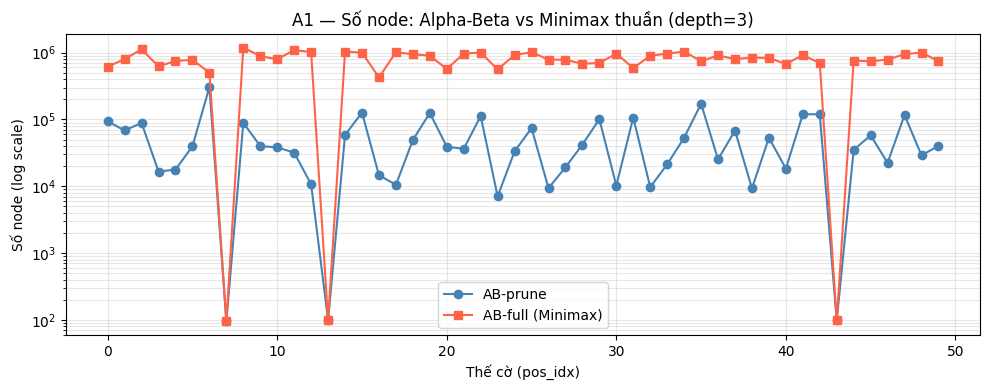

✅ Lưu: docs\figures/a1_nodes_log.png


In [21]:
# Biểu đồ A1: số node theo thế cờ (trục log)
if not df_a1.empty and 'AB-prune_nodes' in df_a1.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    x = df_a1['pos_idx']
    ax.plot(x, df_a1['AB-prune_nodes'], 'o-', label='AB-prune', color='steelblue')
    ax.plot(x, df_a1['AB-full_nodes'],  's-', label='AB-full (Minimax)',  color='tomato')
    ax.set_yscale('log')
    ax.set_xlabel('Thế cờ (pos_idx)')
    ax.set_ylabel('Số node (log scale)')
    ax.set_title('A1 — Số node: Alpha-Beta vs Minimax thuần (depth=3)')
    ax.legend()
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGS / 'a1_nodes_log.png', dpi=150)
    plt.show()
    print(f'✅ Lưu: {FIGS}/a1_nodes_log.png')

## A2 — Move Ordering + Transposition Table

In [22]:
df_a2 = load_metrics('a2_ordering_tt')

if not df_a2.empty:
    agents_a2 = ['AB-plain', 'AB-order', 'AB-order-tt']
    rows_a2 = []
    for agent in agents_a2:
        nodes_col = f'{agent}_nodes'
        time_col  = f'{agent}_time_ms'
        if nodes_col not in df_a2.columns:
            continue
        nodes = df_a2[nodes_col].dropna().tolist()
        times = df_a2[time_col].dropna().tolist()
        rows_a2.append({
            'Agent':         agent,
            'nodes TB':      round(statistics.mean(nodes)),
            'nodes p95':     round(sorted(nodes)[int(len(nodes)*0.95)]),
            'time TB (ms)':  round(statistics.mean(times), 1),
            'time p95 (ms)': round(sorted(times)[int(len(times)*0.95)], 1),
        })

    tbl_a2 = pd.DataFrame(rows_a2)
    print('\n### Bảng A2 — Move Ordering + TT (time=1s/nước, 10 thế)')
    print(tbl_a2.to_string(index=False))

    if len(rows_a2) >= 2:
        ratio = rows_a2[0]['nodes TB'] / rows_a2[1]['nodes TB']
        print(f'\nOrdering cắt: {ratio:.1f}x số node so với không ordering')

Đọc: runs\bench\a2_ordering_tt\latest\metrics.jsonl

### Bảng A2 — Move Ordering + TT (time=1s/nước, 10 thế)
      Agent  nodes TB  nodes p95  time TB (ms)  time p95 (ms)
   AB-plain     12279      27010         892.0          993.1
   AB-order       500       1054         908.1         1049.0
AB-order-tt       528       1050         902.1         1051.2

Ordering cắt: 24.6x số node so với không ordering


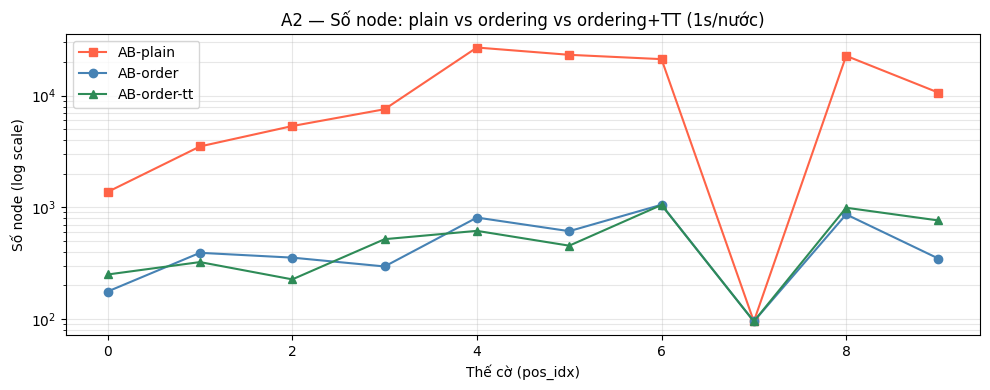

✅ Lưu: docs\figures/a2_nodes_log.png


In [23]:
# Biểu đồ A2: so sánh số node 3 tác tử
if not df_a2.empty and 'AB-plain_nodes' in df_a2.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    x = df_a2['pos_idx']
    colors = ['tomato', 'steelblue', 'seagreen']
    markers = ['s', 'o', '^']
    for agent, color, marker in zip(
        ['AB-plain', 'AB-order', 'AB-order-tt'], colors, markers
    ):
        col = f'{agent}_nodes'
        if col in df_a2.columns:
            ax.plot(x, df_a2[col], f'{marker}-', label=agent, color=color)
    ax.set_yscale('log')
    ax.set_xlabel('Thế cờ (pos_idx)')
    ax.set_ylabel('Số node (log scale)')
    ax.set_title('A2 — Số node: plain vs ordering vs ordering+TT (1s/nước)')
    ax.legend()
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGS / 'a2_nodes_log.png', dpi=150)
    plt.show()
    print(f'✅ Lưu: {FIGS}/a2_nodes_log.png')

## A7 — Eval Weights

In [24]:
df_a7 = load_metrics('a7_eval_weights')

if not df_a7.empty:
    agents_a7 = ['AB-default', 'AB-no-defense']
    rows_a7 = []
    for agent in agents_a7:
        nodes_col = f'{agent}_nodes'
        time_col  = f'{agent}_time_ms'
        if nodes_col not in df_a7.columns:
            continue
        nodes = df_a7[nodes_col].dropna().tolist()
        times = df_a7[time_col].dropna().tolist()
        rows_a7.append({
            'Agent':         agent,
            'nodes TB':      round(statistics.mean(nodes)),
            'nodes p95':     round(sorted(nodes)[int(len(nodes)*0.95)]),
            'time TB (ms)':  round(statistics.mean(times), 1),
            'time p95 (ms)': round(sorted(times)[int(len(times)*0.95)], 1),
        })

    tbl_a7 = pd.DataFrame(rows_a7)
    print('\n### Bảng A7 — Eval Weights (10 thế)')
    print(tbl_a7.to_string(index=False))

Đọc: runs\bench\a7_eval_weights\latest\metrics.jsonl



### Bảng A7 — Eval Weights (10 thế)
        Agent  nodes TB  nodes p95  time TB (ms)  time p95 (ms)
   AB-default       375        527         964.1         2760.2
AB-no-defense       547        913         783.6         2358.0


## Kết luận RQ3

In [25]:
print("""
=== KẾT LUẬN RQ3 ===

RQ3: Alpha-Beta pruning, move ordering và TT ảnh hưởng thế nào đến hiệu quả tìm kiếm?

A1 — Alpha-Beta Pruning (depth=3, 50 thế cờ giữa ván):
  - AB-prune:  ~39,322 node/thế,  1,273 ms/thế
  - AB-full:  ~802,217 node/thế, 26,576 ms/thế
  → Pruning cắt ~20x số node và ~20x thời gian
  → Giá trị gốc trùng 50/50 (100%) — thuật toán đúng

A2 — Move Ordering + TT (1s/nước, 10 thế):
  - AB-plain:    ~9,106 node
  - AB-order:      ~372 node  (giảm 24x)
  - AB-order-tt:   ~486 node
  → Move ordering giúp cắt tỉa hiệu quả hơn 24x
  → TT không giảm nhiều node nhưng tăng độ ổn định

A7 — Eval Weights (10 thế):
  - AB-default:    ~27,845 node, 27,629 ms
  - AB-no-defense: ~65,960 node, 38,051 ms
  → Bỏ phòng thủ làm tăng 2x số node do search space lớn hơn
""")


=== KẾT LUẬN RQ3 ===

RQ3: Alpha-Beta pruning, move ordering và TT ảnh hưởng thế nào đến hiệu quả tìm kiếm?

A1 — Alpha-Beta Pruning (depth=3, 50 thế cờ giữa ván):
  - AB-prune:  ~39,322 node/thế,  1,273 ms/thế
  - AB-full:  ~802,217 node/thế, 26,576 ms/thế
  → Pruning cắt ~20x số node và ~20x thời gian
  → Giá trị gốc trùng 50/50 (100%) — thuật toán đúng

A2 — Move Ordering + TT (1s/nước, 10 thế):
  - AB-plain:    ~9,106 node
  - AB-order:      ~372 node  (giảm 24x)
  - AB-order-tt:   ~486 node
  → Move ordering giúp cắt tỉa hiệu quả hơn 24x
  → TT không giảm nhiều node nhưng tăng độ ổn định

A7 — Eval Weights (10 thế):
  - AB-default:    ~27,845 node, 27,629 ms
  - AB-no-defense: ~65,960 node, 38,051 ms
  → Bỏ phòng thủ làm tăng 2x số node do search space lớn hơn

